In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data  = pd.read_csv('spam.csv', encoding='latin-1')

In [3]:
data.sample(5)

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
2528,ham,jay says he'll put in &lt;#&gt;,NaN,NaN,NaN
1348,ham,"Nothing much, chillin at home. Any super bowl ...",NaN,NaN,NaN
38,ham,Anything lor... U decide...,NaN,NaN,NaN
903,ham,Lovely smell on this bus and it ain't tobacco...,NaN,NaN,NaN
5363,ham,"I think your mentor is , but not 100 percent s...",NaN,NaN,NaN


# Feature Engineering


In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   v1          5572 non-null   str  
 1   v2          5572 non-null   str  
 2   Unnamed: 2  50 non-null     str  
 3   Unnamed: 3  12 non-null     str  
 4   Unnamed: 4  6 non-null      str  
dtypes: str(5)
memory usage: 677.1 KB


## Data Cleaning


In [5]:
data.drop(["Unnamed: 2", "Unnamed: 3", "Unnamed: 4"], axis=1, inplace=True)

In [6]:
data

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will Ì_ b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


In [7]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   v1      5572 non-null   str  
 1   v2      5572 non-null   str  
dtypes: str(2)
memory usage: 541.4 KB


In [8]:
# renaming the columns names
data.rename(columns={"v1": "target", "v2":"text"}, inplace=True)

In [9]:
data

,target,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will Ì_ b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


In [10]:
data["target"].value_counts()

target
ham     4825
spam     747
Name: count, dtype: int64

In [11]:
print(data["target"].unique())

<ArrowStringArray>
['ham', 'spam']
Length: 2, dtype: str


In [12]:
# data["target"] = data["target"].map({
#     "ham": 0,
#     "spam": 1
# })


# or i can go with label encoder
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
data["target"] = le.fit_transform(data["target"])

In [13]:
data["target"].value_counts()

target
0    4825
1     747
Name: count, dtype: int64

In [14]:
# checking the null values
data.isnull().sum()

target    0
text      0
dtype: int64

In [15]:
#  checking the duplicate values
data.duplicated().sum()

np.int64(403)

In [16]:
# remove the duplicate values
data.drop_duplicates(inplace=True, keep="first")

In [17]:
data.duplicated().sum()

np.int64(0)

In [18]:
data.shape

(5169, 2)

# EDA (Exploratory Data Analysis)

In [19]:
data["target"].value_counts()

target
0    4516
1     653
Name: count, dtype: int64

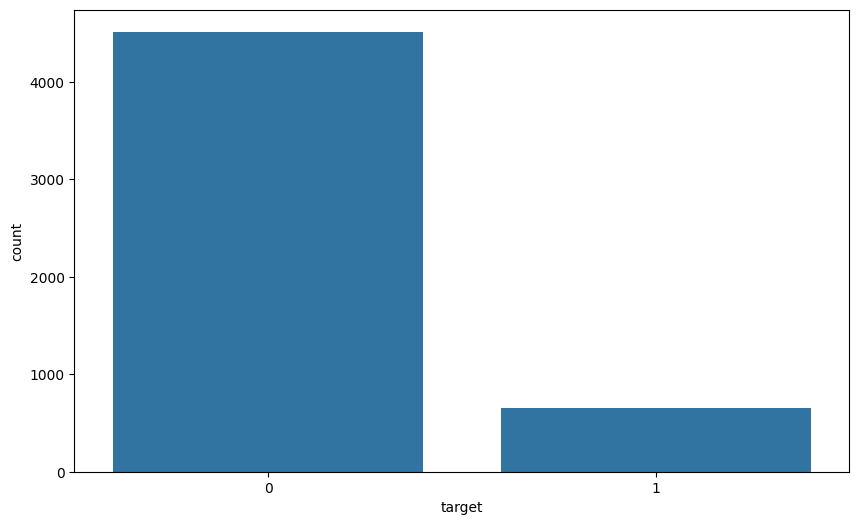

In [20]:
plt.figure(figsize=(10, 6))

sns.countplot(x="target", data=data)
plt.show()


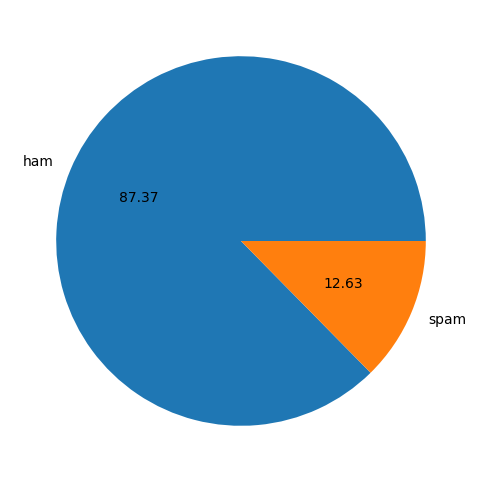

In [21]:
# pie chart
plt.figure(figsize=(10, 6))

plt.pie(data["target"].value_counts(), labels=["ham", "spam"], autopct="%0.2f")
plt.show()

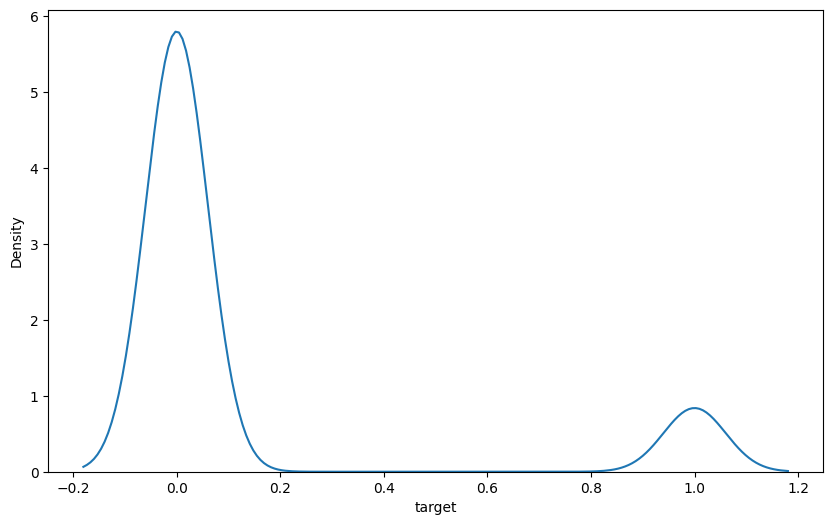

In [22]:
# checking the data is normally distributed or not
plt.figure(figsize=(10, 6))

sns.kdeplot(data["target"])
plt.show()

In [23]:
!pip install nltk


In [24]:
import nltk
nltk.download("punkt")
nltk.download("stopwords")
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to
[nltk_data]     /Users/mohddanish/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/mohddanish/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/mohddanish/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [25]:
# length of the each sentence in the data
data["num_characters"] = data["text"].apply(lambda x:len(x))
# data["text"].apply(len)

In [26]:
data

,target,text,num_characters
0,0,"Go until jurong point, crazy.. Available only ...",111
1,0,Ok lar... Joking wif u oni...,29
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,0,U dun say so early hor... U c already then say...,49
4,0,"Nah I don't think he goes to usf, he lives aro...",61
...,...,...,...
5567,1,This is the 2nd time we have tried 2 contact u...,161
5568,0,Will Ì_ b going to esplanade fr home?,37
5569,0,"Pity, * was in mood for that. So...any other s...",57
5570,0,The guy did some bitching but I acted like i'd...,125


In [27]:
# now breaking the text into words

# data["num_words"] = data["text"].apply(lambda x:len(x.split(" ")))
# or
data["num_words"] = data["text"].apply(lambda x:len(nltk.word_tokenize(x)))

In [28]:
data

,target,text,num_characters,num_words
0,0,"Go until jurong point, crazy.. Available only ...",111,24
1,0,Ok lar... Joking wif u oni...,29,8
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37
3,0,U dun say so early hor... U c already then say...,49,13
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15
...,...,...,...,...
5567,1,This is the 2nd time we have tried 2 contact u...,161,35
5568,0,Will Ì_ b going to esplanade fr home?,37,9
5569,0,"Pity, * was in mood for that. So...any other s...",57,15
5570,0,The guy did some bitching but I acted like i'd...,125,27


In [29]:
# breaking the text into sentences
data["num_sentences"] = data["text"].apply(lambda x:len(nltk.sent_tokenize(x)))

In [30]:
data

,target,text,num_characters,num_words,num_sentences
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2
1,0,Ok lar... Joking wif u oni...,29,8,2
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2
3,0,U dun say so early hor... U c already then say...,49,13,1
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1
...,...,...,...,...,...
5567,1,This is the 2nd time we have tried 2 contact u...,161,35,4
5568,0,Will Ì_ b going to esplanade fr home?,37,9,1
5569,0,"Pity, * was in mood for that. So...any other s...",57,15,2
5570,0,The guy did some bitching but I acted like i'd...,125,27,1


In [31]:
nltk.sent_tokenize(data["text"][0])

['Go until jurong point, crazy..',
 'Available only in bugis n great world la e buffet... Cine there got amore wat...']

In [32]:
data[["num_characters", "num_words", "num_sentences"]].describe()

,num_characters,num_words,num_sentences
count,5169.000000,5169.000000,5169.000000
mean,78.977945,18.455794,1.965564
std,58.236293,13.324758,1.448541
min,2.000000,1.000000,1.000000
25%,36.000000,9.000000,1.000000
50%,60.000000,15.000000,1.000000
75%,117.000000,26.000000,2.000000
max,910.000000,220.000000,38.000000


In [33]:
# spam - 1
# not spam -2

data[data["target"] == 0][
    ["num_characters", "num_words", "num_sentences"]
]

data[data["target"] == 0][
    ["num_characters", "num_words", "num_sentences"]
].describe()

,num_characters,num_words,num_sentences
count,4516.000000,4516.000000,4516.000000
mean,70.459256,17.123782,1.820195
std,56.358207,13.493970,1.383657
min,2.000000,1.000000,1.000000
25%,34.000000,8.000000,1.000000
50%,52.000000,13.000000,1.000000
75%,90.000000,22.000000,2.000000
max,910.000000,220.000000,38.000000


In [ ]:
data[data["target"] == 1][
    ["num_characters", "num_words", "num_sentences"]
]

data[data["target"] == 1][
    ["num_characters", "num_words", "num_sentences"]
].describe()

,num_characters,num_words,num_sentences
count,653.000000,653.000000,653.000000
mean,137.891271,27.667688,2.970904
std,30.137753,7.008418,1.488425
min,13.000000,2.000000,1.000000
25%,132.000000,25.000000,2.000000
50%,149.000000,29.000000,3.000000
75%,157.000000,32.000000,4.000000
max,224.000000,46.000000,9.000000


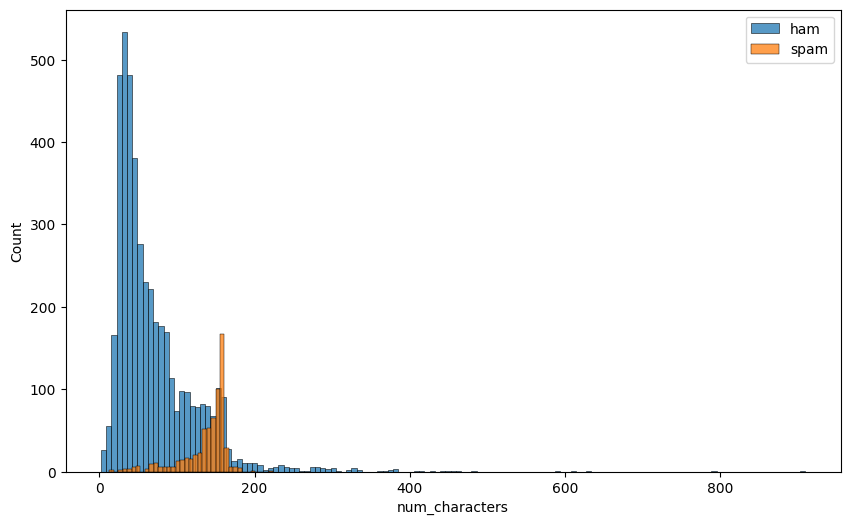

In [34]:
# ploting histogram of spam and ham

plt.figure(figsize=(10, 6))

sns.histplot(data[data["target"] == 0]["num_characters"], label="ham")
sns.histplot(data[data["target"] == 1]["num_characters"], label="spam")
plt.legend()
plt.show()

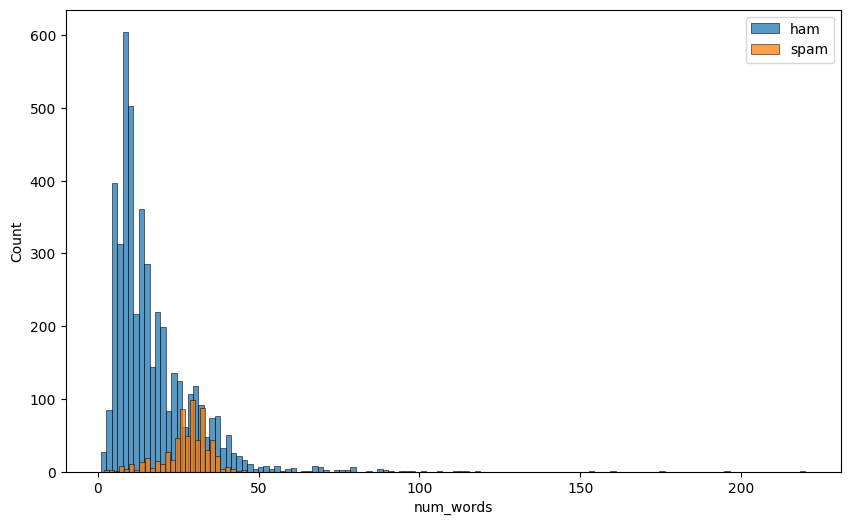

In [35]:
plt.figure(figsize=(10, 6))

sns.histplot(data[data["target"] == 0]["num_words"], label="ham")
sns.histplot(data[data["target"] == 1]["num_words"], label="spam")
plt.legend()
plt.show()

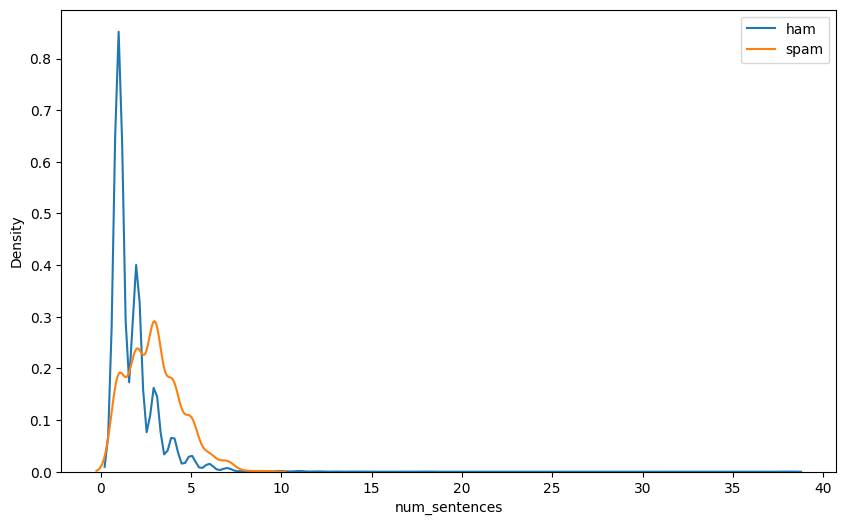

In [36]:
plt.figure(figsize=(10, 6))

sns.kdeplot(data[data["target"] == 0]["num_sentences"], label="ham")
sns.kdeplot(data[data["target"] == 1]["num_sentences"], label="spam")
plt.legend()
plt.show()

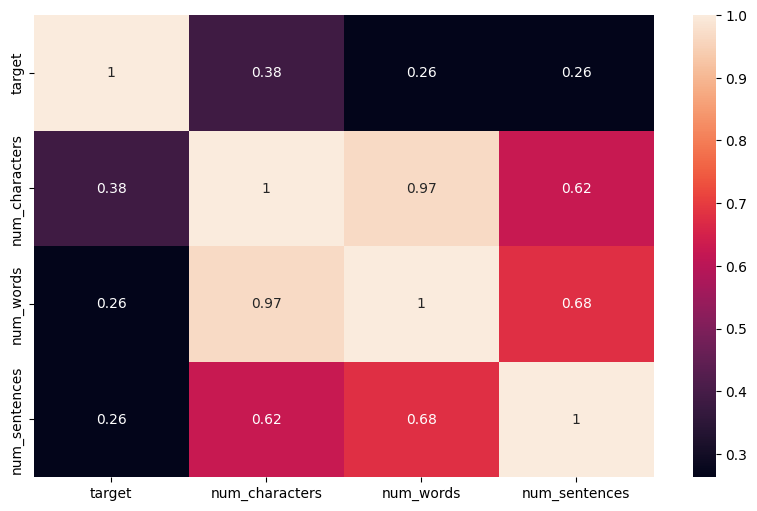

In [37]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    data.select_dtypes(include="number").corr(),
    annot=True
)

plt.show()

<Figure size 1000x600 with 0 Axes>

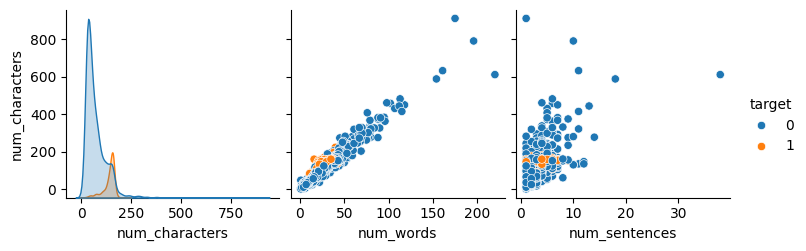

<Figure size 1000x600 with 0 Axes>

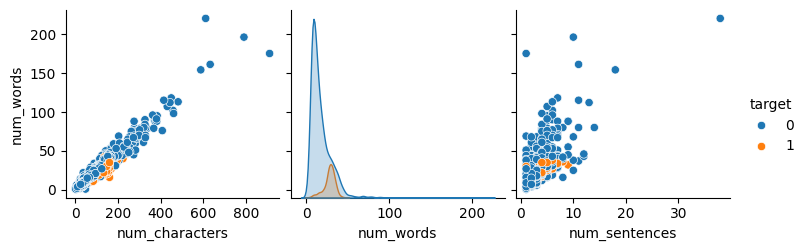

<Figure size 1000x600 with 0 Axes>

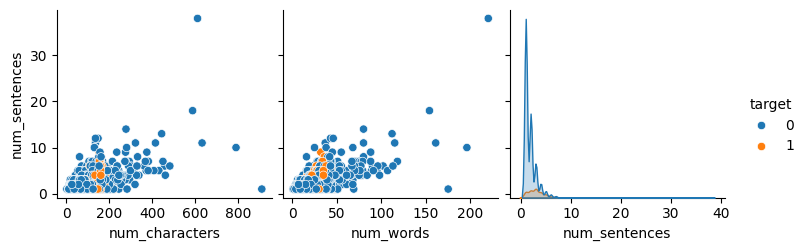

In [38]:
cols = ["num_characters", "num_words", "num_sentences"]
for col in cols:
    plt.figure(figsize=(10, 6))
    sns.pairplot(data, x_vars=cols, y_vars=col, hue="target")
    plt.show()

Data Processing
```
      . lower case
      . tokenization(breaking sentences into the words)
      . removing special characters(removing the special characters)
      . removing stop words and punctuation(stop word ->[are, is, the, I, am and etc], punctuation[, . ! @ # and etc])
      . stemming = Removing word endings.
      . lemmatization = Converting words into their meaningful dictionary base form.
```
      

In [39]:
data

,target,text,num_characters,num_words,num_sentences
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2
1,0,Ok lar... Joking wif u oni...,29,8,2
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2
3,0,U dun say so early hor... U c already then say...,49,13,1
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1
...,...,...,...,...,...
5567,1,This is the 2nd time we have tried 2 contact u...,161,35,4
5568,0,Will Ì_ b going to esplanade fr home?,37,9,1
5569,0,"Pity, * was in mood for that. So...any other s...",57,15,2
5570,0,The guy did some bitching but I acted like i'd...,125,27,1


In [40]:
from nltk.corpus import stopwords
import string
import nltk

def DataPreprocessing(text):
    text = text.lower()
    text = nltk.word_tokenize(text)

    y = []

    # Removing special characters
    for i in text:
        if i.isalnum():
            y.append(i)
    
    text = y[:]
    y.clear()


    # Removing stop words and punctuations
    for i in text:
        if i not in stopwords.words("english") and i not in string.punctuation:
            y.append(i)

    text = y[:]
    y.clear()

    # stemming -> concept of stemming is to convert a word to its root word like "going" to "go", "gone"
    ps = nltk.PorterStemmer()
    for i in text:
        y.append(ps.stem(i))

    text = y[:]
    y.clear()
    
    return " ".join(text)


In [41]:
# passing actual data text to function
data["transformed_text"] = data["text"].apply(DataPreprocessing)

In [42]:
text = DataPreprocessing("Hello my name is Mohd Danish. Here We have the Special characters such as $, #, @, I loving to write the code and train the machine learning models")
print(text)

hello name mohd danish special charact love write code train machin learn model


In [43]:
data

,target,text,num_characters,num_words,num_sentences,transformed_text
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2,go jurong point crazi avail bugi n great world...
1,0,Ok lar... Joking wif u oni...,29,8,2,ok lar joke wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2,free entri 2 wkli comp win fa cup final tkt 21...
3,0,U dun say so early hor... U c already then say...,49,13,1,u dun say earli hor u c alreadi say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1,nah think goe usf live around though
...,...,...,...,...,...,...
5567,1,This is the 2nd time we have tried 2 contact u...,161,35,4,2nd time tri 2 contact u pound prize 2 claim e...
5568,0,Will Ì_ b going to esplanade fr home?,37,9,1,b go esplanad fr home
5569,0,"Pity, * was in mood for that. So...any other s...",57,15,2,piti mood suggest
5570,0,The guy did some bitching but I acted like i'd...,125,27,1,guy bitch act like interest buy someth els nex...


In [44]:
array = [1,2,3,4,5,6]

# list comprehension
result = [x**2 for x in array]
print(result)

# map function with lambda function
result = list(map(lambda x: x**2, array))
print(result)

[1, 4, 9, 16, 25, 36]
[1, 4, 9, 16, 25, 36]


In [45]:
!pip install wordcloud

In [46]:
from wordcloud import WordCloud
wc = WordCloud(width=1000, height=1000, min_font_size=10, background_color="white")

In [47]:
# spam_wc = wc.generate(data[data["target"] == 1]["transformed_text"].sum())
spam_wc = wc.generate(data[data["target"] == 1]["transformed_text"].str.cat(sep=" "))

In [48]:
data[data["target"] == 1]["transformed_text"].sum()

'free entri 2 wkli comp win fa cup final tkt 21st may text fa 87121 receiv entri question std txt rate c appli 08452810075over18freemsg hey darl 3 week word back like fun still tb ok xxx std chg send rcvwinner valu network custom select receivea prize reward claim call claim code kl341 valid 12 hourmobil 11 month u r entitl updat latest colour mobil camera free call mobil updat co free 08002986030six chanc win cash 100 pound txt csh11 send cost 6day tsandc appli repli hl 4 infourgent 1 week free membership prize jackpot txt word claim 81010 c lccltd pobox 4403ldnw1a7rw18xxxmobilemovieclub use credit click wap link next txt messag click httpengland v macedonia dont miss news txt ur nation team 87077 eg england 87077 tri wale scotland poboxox36504w45wqthank subscript rington uk mobil charg pleas confirm repli ye repli charg07732584351 rodger burn msg tri call repli sm free nokia mobil free camcord pleas call 08000930705 deliveri tomorrowsm ac sptv new jersey devil detroit red wing play i

In [49]:
spam_wc

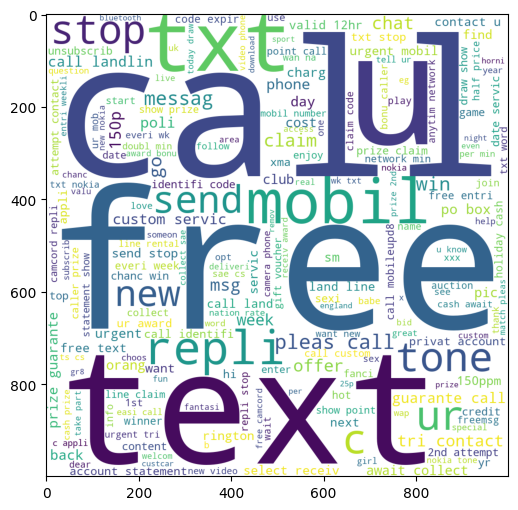

In [50]:
plt.figure(figsize=(10, 6))
plt.imshow(spam_wc)

In [51]:
not_spam_wc = wc.generate(data[data["target"] == 0]["transformed_text"].str.cat(sep=" "))

In [52]:
not_spam_wc

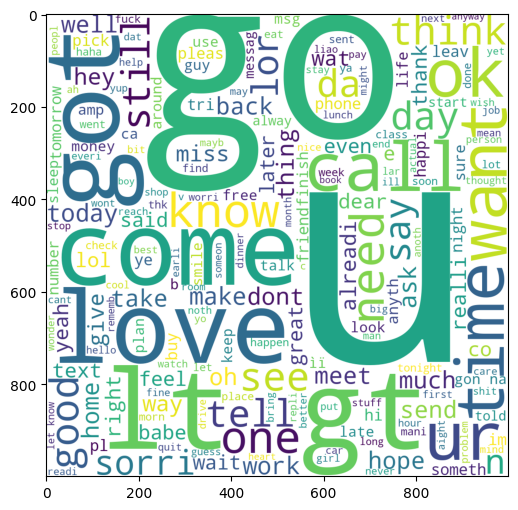

In [53]:
plt.figure(figsize=(10, 6))
plt.imshow(not_spam_wc)

In [54]:
# counting the top 30 word in the spam message or which word repeating the most

store = data[data["target"] == 1]["transformed_text"].str.split().explode().value_counts().head(30)
type(store)

pandas.Series

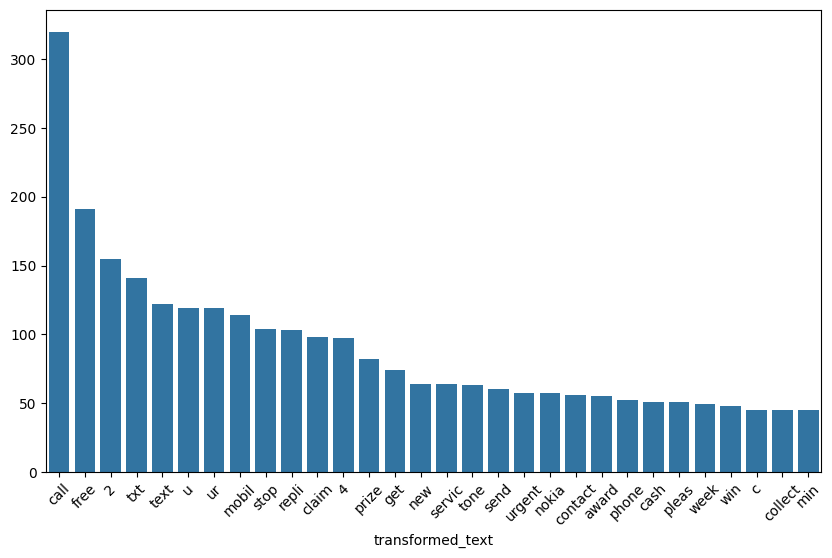

In [55]:
plt.figure(figsize=(10, 6))
sns.barplot(x=store.index, y=store.values)
plt.xticks(rotation=45)
plt.show()

In [57]:
spam_corpus = []

for message in data[data["target"] == 1]["transformed_text"].str.split():
    spam_corpus.append(" ".join(message))
spam_corpus = " ".join(spam_corpus)
spam_corpus

'free entri 2 wkli comp win fa cup final tkt 21st may text fa 87121 receiv entri question std txt rate c appli 08452810075over18 freemsg hey darl 3 week word back like fun still tb ok xxx std chg send rcv winner valu network custom select receivea prize reward claim call claim code kl341 valid 12 hour mobil 11 month u r entitl updat latest colour mobil camera free call mobil updat co free 08002986030 six chanc win cash 100 pound txt csh11 send cost 6day tsandc appli repli hl 4 info urgent 1 week free membership prize jackpot txt word claim 81010 c lccltd pobox 4403ldnw1a7rw18 xxxmobilemovieclub use credit click wap link next txt messag click http england v macedonia dont miss news txt ur nation team 87077 eg england 87077 tri wale scotland poboxox36504w45wq thank subscript rington uk mobil charg pleas confirm repli ye repli charg 07732584351 rodger burn msg tri call repli sm free nokia mobil free camcord pleas call 08000930705 deliveri tomorrow sm ac sptv new jersey devil detroit red w

In [58]:
pip install --upgrade pip

Note: you may need to restart the kernel to use updated packages.


In [59]:
!pip install collection

In [60]:
from collections import Counter

spam_counter = Counter(spam_corpus.split())
ss = spam_counter.most_common(30)

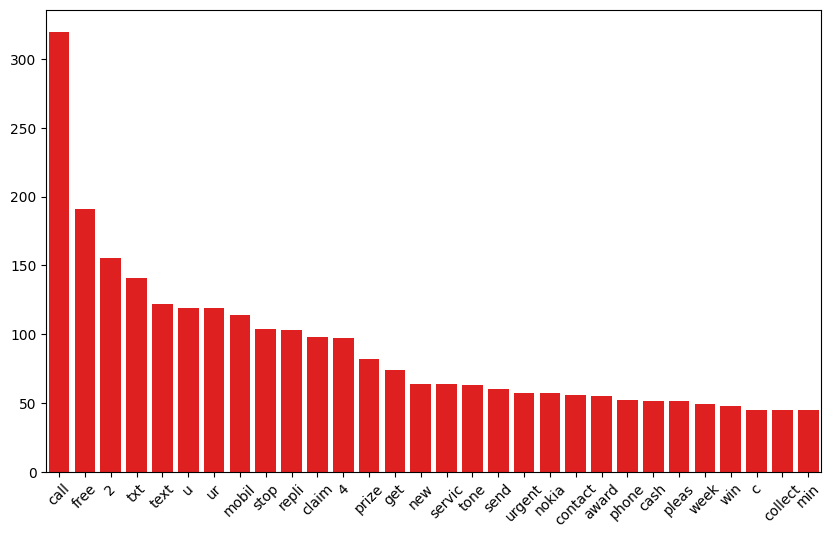

In [61]:
plt.figure(figsize=(10, 6))
sns.barplot(x=[x[0] for x in ss], y=[x[1] for x in ss], color="red")
# do xticks
plt.xticks(rotation=45)
plt.show()

In [62]:
import pandas as pd

data = pd.Series([
    "I love machine learning",
    "I love Python",
    "Python is interesting"
])

In [68]:
result = data.str.split()
result

0    [I, love, machine, learning]
1               [I, love, Python]
2       [Python, is, interesting]
dtype: object

In [64]:
print(result)

0    [I, love, machine, learning]
1               [I, love, Python]
2       [Python, is, interesting]
dtype: object


In [65]:
result = data.str.split().explode()

print(result)

0              I
0           love
0        machine
0       learning
1              I
1           love
1         Python
2         Python
2             is
2    interesting
dtype: str


In [66]:

print(result.value_counts().head(3))

I         2
love      2
Python    2
Name: count, dtype: int64


In [67]:
store

transformed_text
call       320
free       191
2          155
txt        141
text       122
u          119
ur         119
mobil      114
stop       104
repli      103
claim       98
4           97
prize       82
get         74
new         64
servic      64
tone        63
send        60
urgent      57
nokia       57
contact     56
award       55
phone       52
cash        51
pleas       51
week        49
win         48
c           45
collect     45
min         45
Name: count, dtype: int64